# Example 03 — Switch models

Same toy **regression** as example 01. Change **one YAML key**: `modeling.model_selection` (default: `randomforest`).

You should not copy-paste a new training script for ExtraTrees vs Ridge vs Random Forest.

## Learning objectives

- Swap the estimator without rewriting Python.
- See the architecture in `models/*randomforest*regressor*.pkl` (not in the PNG name).

### YAML

```yaml
modeling:
  model_selection: randomforest   # try: extratrees, ridge, elasticnet, linear
```

```bash
python -m run_pipeline --config examples/03_switch_models/config.yaml --force-retrain
```

[Open in Colab](https://colab.research.google.com/github/Oikiy/ML-MEM-Review/blob/main/examples/03_switch_models/Colab.ipynb)


## 1. Bootstrap (Colab clone + install)

This `.ipynb` is not the whole **repository** (`config.yaml`, `src/`, data).

> **Next cell:** on Colab, clone/update `/content/ML-MEM-Review` and pip-install. First install can take a few minutes. No Google Drive. Locally: find the repo (example 05 installs Ax if missing).

### How to read the output

`Repo root: ...` and `Colab bootstrap done.`

---

**Watch out.** Do not run later cells first. Expand the hidden **Bootstrap** form if clone/install fails. Then run **in order**.


In [1]:
# @title Bootstrap (clone + install)
# === COLAB BOOTSTRAP (safe locally) =========================================
import os
import sys
import subprocess
from pathlib import Path

def _in_colab() -> bool:
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def _run(cmd, **kwargs):
    print("+", " ".join(cmd) if isinstance(cmd, (list, tuple)) else cmd)
    subprocess.check_call(cmd, **kwargs)

def _find_repo_root(start: Path):
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").is_file() and (candidate / "src").is_dir():
            return candidate
    return None

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

IN_COLAB = _in_colab()
REPO_URL = os.environ.get("ML_MEM_REPO_URL", "https://github.com/Oikiy/ML-MEM-Review.git")
REPO_NAME = os.environ.get("ML_MEM_REPO_NAME", "ML-MEM-Review")
REPO_REF = os.environ.get("ML_MEM_REPO_REF", "main")
COLAB_ROOT = Path(os.environ.get("ML_MEM_COLAB_ROOT", f"/content/{REPO_NAME}"))
EXTRAS = ''

def _git_head(repo: Path) -> str:
    try:
        return subprocess.check_output(
            ["git", "-C", str(repo), "rev-parse", "HEAD"], text=True
        ).strip()
    except (subprocess.CalledProcessError, FileNotFoundError, OSError):
        return ""

def _truthy(name: str) -> bool:
    return os.environ.get(name, "").strip().lower() in {"1", "true", "yes"}

if IN_COLAB:
    try:
        if COLAB_ROOT.exists() and (COLAB_ROOT / ".git").is_dir():
            if _truthy("ML_MEM_SKIP_PULL"):
                print(f"Skipping git update at {COLAB_ROOT} (ML_MEM_SKIP_PULL=1)")
            else:
                print(f"Updating clone at {COLAB_ROOT} to origin/{REPO_REF}")
                _run(["git", "-C", str(COLAB_ROOT), "fetch", "--depth", "1", "origin", REPO_REF])
                _run(["git", "-C", str(COLAB_ROOT), "reset", "--hard", "FETCH_HEAD"])
        elif not COLAB_ROOT.exists():
            _run(["git", "clone", "--depth", "1", "--branch", REPO_REF, REPO_URL, str(COLAB_ROOT)])
        os.chdir(COLAB_ROOT)
    except subprocess.CalledProcessError as exc:
        raise RuntimeError(
            "git clone/update failed. Make the repo public, set ML_MEM_REPO_URL "
            f"to a fork, or set ML_MEM_REPO_REF. Original error: {exc}"
        ) from exc
    root = _find_repo_root(Path.cwd())
else:
    root = _find_repo_root(Path.cwd())

if root is None:
    raise RuntimeError(
        "Could not locate ML-MEM-Review (need config.yaml + src/). "
        "On Colab: re-run this cell after a successful clone. "
        "Locally: open from inside a full clone of the repository."
    )

os.chdir(root)
print(f"Repo root: {root}  git={_git_head(root)[:12]}")

src = root / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

if IN_COLAB:
    marker = root / ".colab_install_ok"
    force = _truthy("ML_MEM_FORCE_INSTALL")
    head = _git_head(root)
    extras = EXTRAS
    pip_spec = str(root) if not extras else f"{root}[{extras}]"
    install_key = f"{head}\n{extras}"
    prev = marker.read_text(encoding="utf-8").strip() if marker.is_file() else ""
    if force or prev != install_key:
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", pip_spec])
        try:
            marker.write_text(install_key + "\n", encoding="utf-8")
        except OSError:
            pass
    else:
        print("Skipping pip install (clone SHA + extras unchanged). Set ML_MEM_FORCE_INSTALL=1 to reinstall.")
    print("Colab bootstrap done.")
else:
    print("Local session: repo root + src/ on path (no auto pip install).")

REPO_ROOT = root
# === end bootstrap ===========================================================


Repo root: C:\Users\kqyan\Github\ML-MEM-Review  git=c3dd9d5a26ad
Local session: repo root + src/ on path (no auto pip install).


## What this config emphasizes

The knob is **`modeling.model_selection`**. Same CSV and `features.mode: auto` as example 01.

Linear models still use the same preprocessing; SHAP may skip them. This example does not run SHAP or Ax.

---

**Try.** After the first run, change that one key, re-run with `--force-retrain`, and check `models/`.


## 2. Read `config.yaml`

Print this example’s YAML. Nothing is trained yet.

> **Next cell:** the keys listed under “What this config emphasizes.”

This gallery teaches *configuration*: change YAML, not Python, to reuse `run_pipeline`.

---

**Try.** Name the **target** column you expect the model to predict before you run the pipeline.


In [2]:
# Show the example config (edit the file under examples/ to experiment)
from pathlib import Path

CONFIG_REL = "examples/03_switch_models/config.yaml"
CONFIG_PATH = REPO_ROOT / CONFIG_REL
assert CONFIG_PATH.is_file(), f"Missing {CONFIG_PATH} — bootstrap/clone incomplete?"

print(CONFIG_PATH.read_text(encoding="utf-8"))



# Switch models example — same data, different model_selection.
# Run from repo root:
#   python -m run_pipeline --config examples/03_switch_models/config.yaml --stage model

project:
  name: "example_03_switch_models"

data:
  dataset: "toy_regression.csv"
  sheet: ""
  targets: ["permeance"]

features:
  mode: "auto"

modeling:
  # Change only this line to try another architecture:
  model_selection: "randomforest"
  # regression options:
  #   extratrees | randomforest | histgradientboosting | ridge | elasticnet | linear
  task: "regression"
  use_hyperparam_tuning: false
  n_estimators: 100
  random_state: 42
  cv_folds: 3



## 3. Run the pipeline

Call `python -m run_pipeline` for this folder, **one stage at a time** (EDA, then model; example 05 also optimize).

> **Next cell:** `Pipeline finished`. Artifacts land under `examples/03_switch_models/`, not inside the notebook. On Colab, open `outputs/figures` in the file browser.

---

**Watch out.** The red `RuntimeError` is only a wrapper — read the traceback **above** it. `--force-retrain` rebuilds models after YAML edits.


In [3]:
# Run the pipeline (artifacts written under examples/03_switch_models/)
import os
import subprocess
import sys
from pathlib import Path

env = os.environ.copy()
src = str(Path(REPO_ROOT) / "src")
env["PYTHONPATH"] = src + os.pathsep + env.get("PYTHONPATH", "")
base = [sys.executable, "-m", "run_pipeline", "--config", str(CONFIG_PATH), "--force-retrain"]
for stage in ("eda", "model"):
    cmd = base + ["--stage", stage]
    print("+", " ".join(cmd))
    completed = subprocess.run(
        cmd, cwd=str(REPO_ROOT), env=env, text=True, capture_output=True
    )
    if completed.stdout:
        print(completed.stdout)
    if completed.returncode != 0:
        if completed.stderr:
            print(completed.stderr)
        err = (completed.stderr or completed.stdout or "").strip()
        raise RuntimeError(
            f"run_pipeline --stage {stage} exited {completed.returncode}.\n\n{err[-8000:]}"
        )
print("Done.")



+ c:\Users\kqyan\anaconda3\python.exe -m run_pipeline --config C:\Users\kqyan\Github\ML-MEM-Review\examples\03_switch_models\config.yaml --force-retrain --stage eda

Loaded dataset: toy_regression.csv
DATASET CHECK
Rows: 60   Columns: 5

Targets:
  [OK]   permeance

Features used (4):
  - temperature_C
  - pressure_bar
  - additive_wt_pct
  - catalyst
No feature_engineering.lookups configured; skipping enrichment lookups.
EDA figures saved to: C:\Users\kqyan\Github\ML-MEM-Review\examples\03_switch_models\outputs/figures

Pipeline finished. Figures are in: C:\Users\kqyan\Github\ML-MEM-Review\examples\03_switch_models\outputs/figures

+ c:\Users\kqyan\anaconda3\python.exe -m run_pipeline --config C:\Users\kqyan\Github\ML-MEM-Review\examples\03_switch_models\config.yaml --force-retrain --stage model

Loaded dataset: toy_regression.csv
DATASET CHECK
Rows: 60   Columns: 5

Targets:
  [OK]   permeance

Features used (4):
  - temperature_C
  - pressure_bar
  - additive_wt_pct
  - catalyst
No 

## 4. Figures

### Distribution and heatmap

Same as example 01. These plots do **not** change when you switch `model_selection` — only the **model** does.

### Parity plot

Measured vs predicted. **Diagonal** = perfect. Compare **test** points after you change the model, not only the training cloud. Filename stays `parity_permeance.png`; the architecture is in the `.pkl` name.

---

**Try.** Would Ridge and Random Forest land on the same test RMSE on a wiggly toy curve?


### target_distributions.png

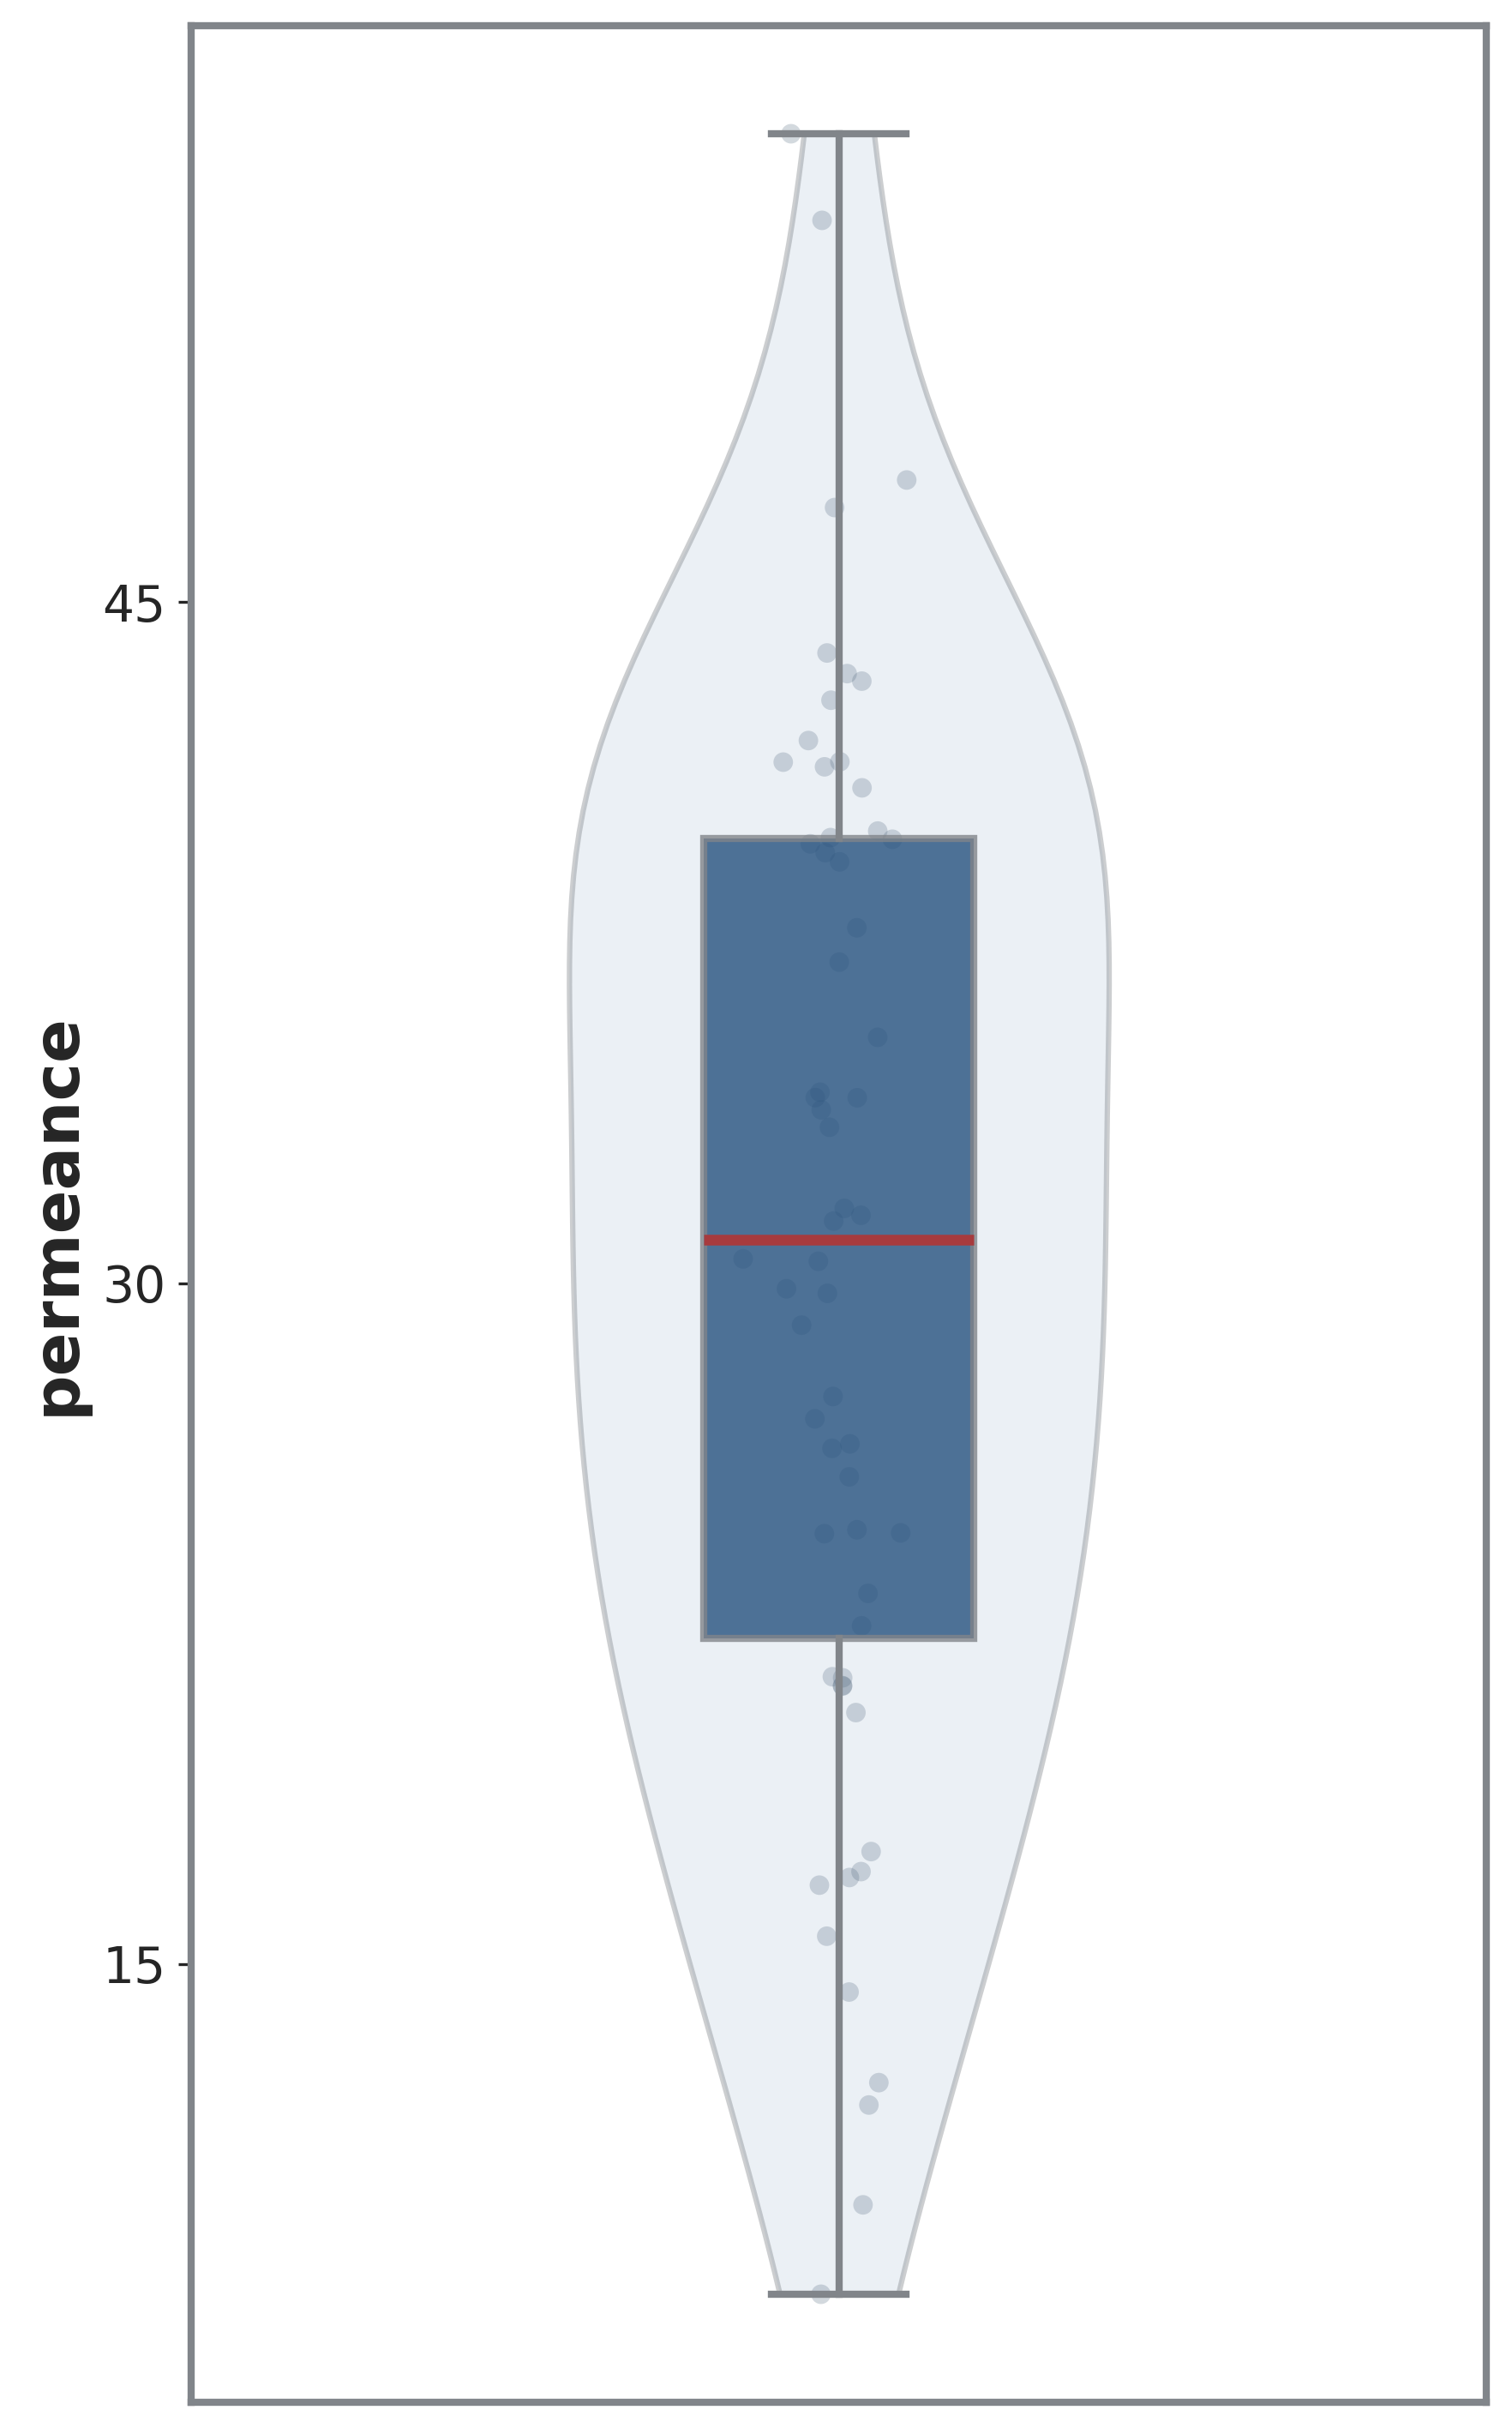

### pearson_heatmap.png

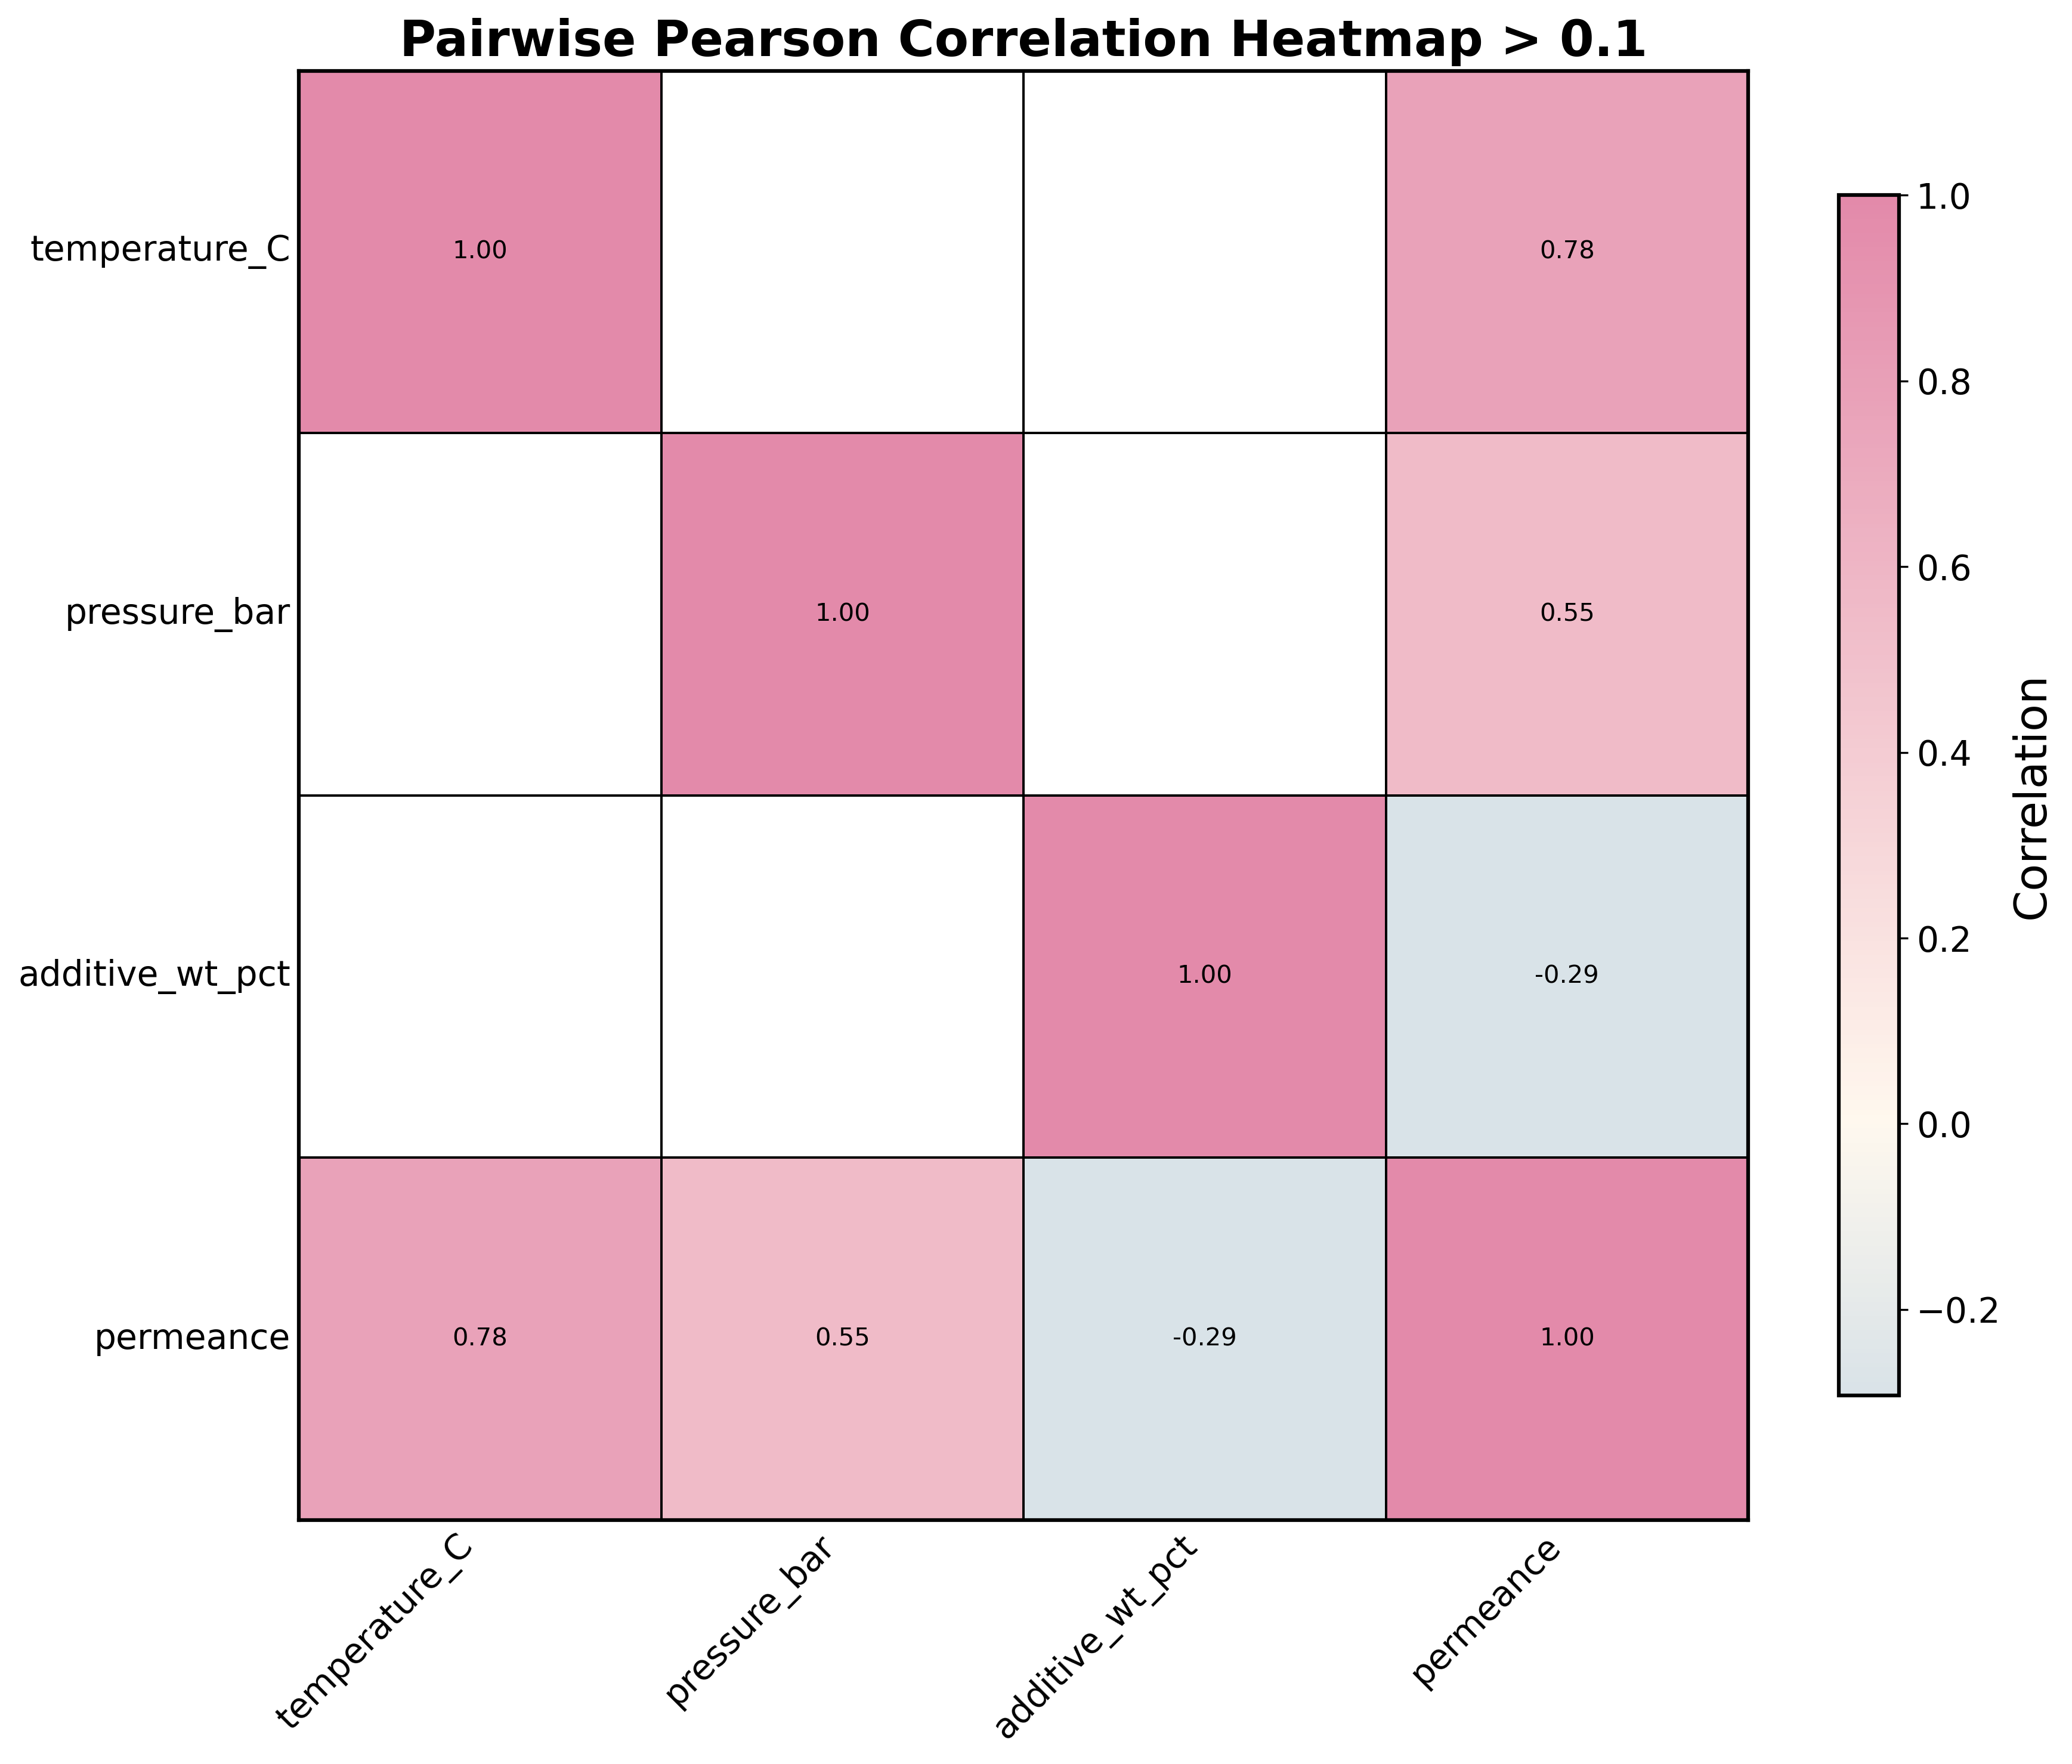

### parity_permeance.png

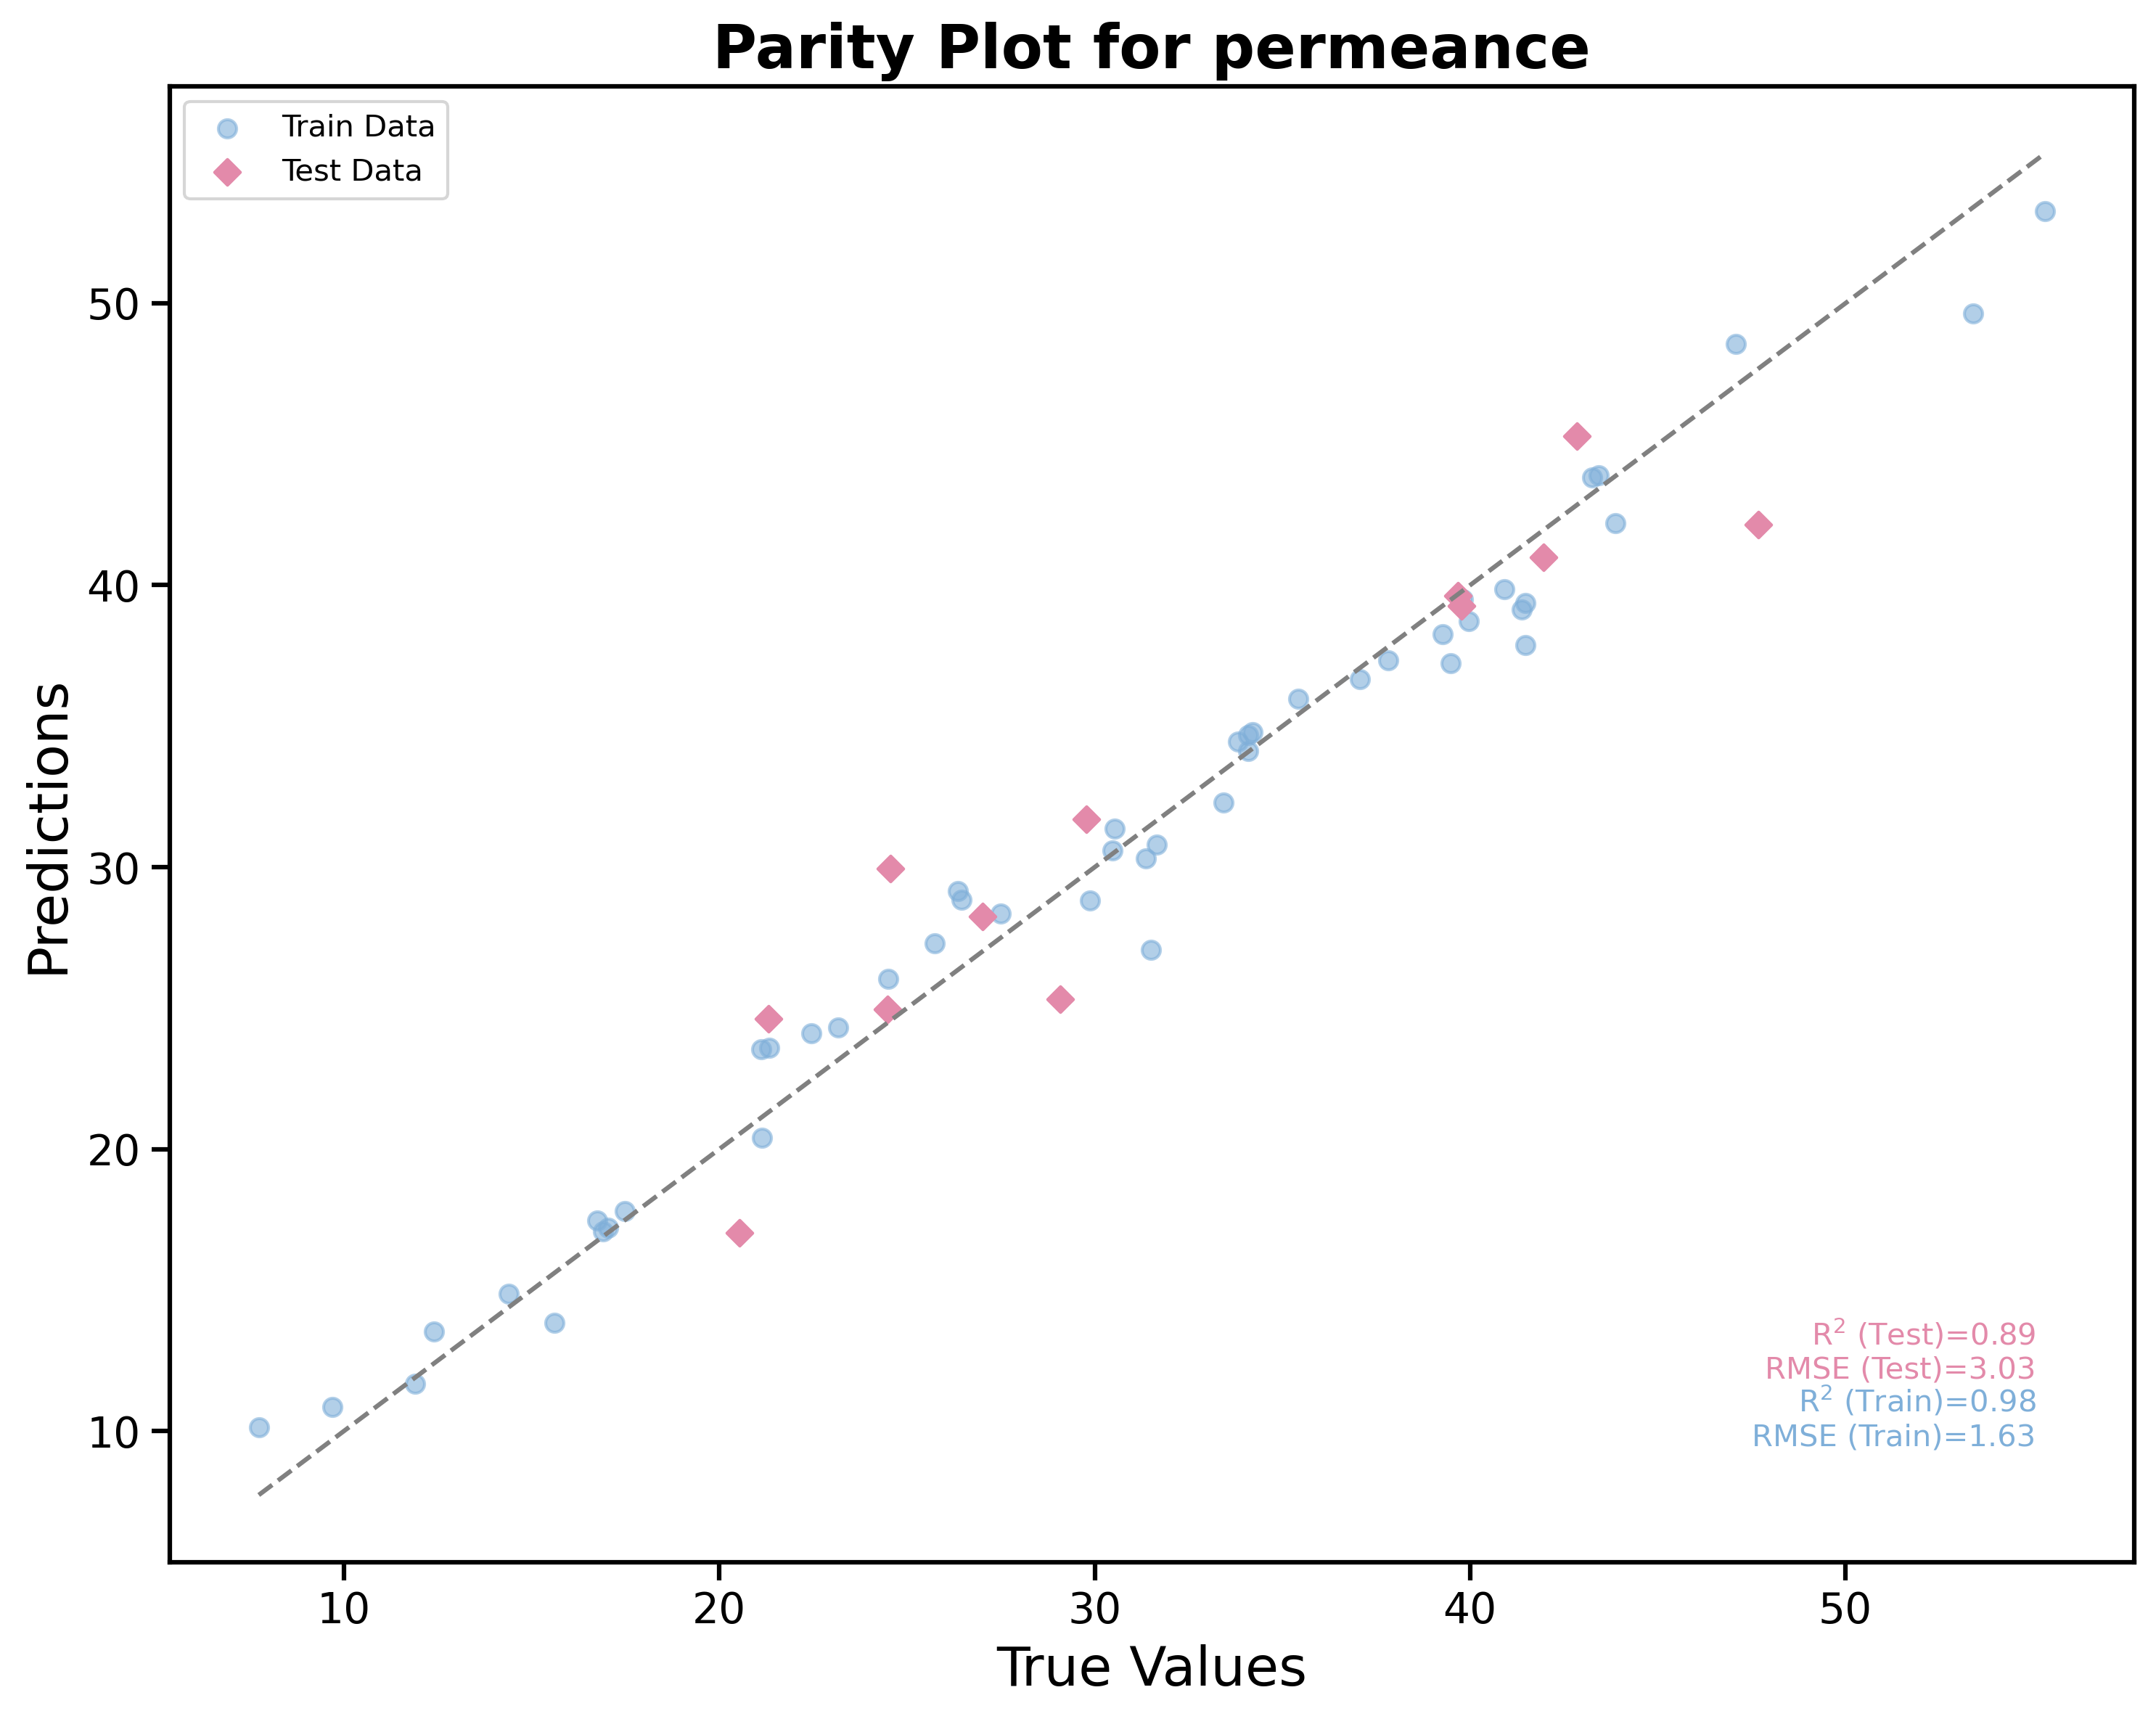

In [4]:
# @title Show figures
from pathlib import Path
from IPython.display import display, Markdown, Image

fig_dir = REPO_ROOT / "examples" / "03_switch_models" / "outputs" / "figures"
for name in [
    "target_distributions.png",
    "pearson_heatmap.png",
    "parity_permeance.png",
]:
    path = fig_dir / name
    if path.is_file():
        display(Markdown(f"### {name}"))
        display(Image(filename=str(path)))


## Try next

- Set `model_selection: ridge` and compare test error.
- Example 04: choose **columns**, not estimators.
- Full tutorial: [`Ml-MEM-Tut.ipynb`](../../notebooks/Complete_notebook/Ml-MEM-Tut.ipynb)
